 Install Dependencies

In [1]:
!pip install fathomnet torch torchvision matplotlib seaborn scikit-learn pandas numpy tqdm Pillow requests


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.4/300.4 kB 18.6 MB/s eta 0:00:00


Imports & Global Seed

In [2]:
# Imports and reproducibility setup
import os
import re
import sys
import copy
import json
import random
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix, classification_report
)
from IPython.display import display
from fathomnet.api import images, boundingboxes

#Reproducibility
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Seed set to {SEED}")
print(f"🖥️  Using device: {DEVICE}")


✅ Seed set to 42
🖥️  Using device: cuda


Define Species & OOD Split

In [3]:
# select top concepts from FathomNet
NUM_KNOWN   = 10
NUM_OOD     = 2
MIN_IMAGES  = 120

DATA_DIR = Path("fathomnet_data")
DATA_DIR.mkdir(exist_ok=True)

print("📡 Querying FathomNet for concept counts...")
concepts_data = sorted(
    boundingboxes.count_total_by_concept(),
    key=lambda x: getattr(x, "count", 0),
    reverse=True,
)

# Filter to concepts that have at least MIN_IMAGES annotations
eligible = [c.concept for c in concepts_data if getattr(c, "count", 0) >= MIN_IMAGES]
selected = eligible[: NUM_KNOWN + NUM_OOD]

if len(selected) < NUM_KNOWN + NUM_OOD:
    raise ValueError(
        f"Only {len(selected)} viable concepts found, need {NUM_KNOWN + NUM_OOD}."
    )

KNOWN_CONCEPTS = selected[:NUM_KNOWN]
OOD_CONCEPTS   = selected[NUM_KNOWN:]
ALL_CONCEPTS   = KNOWN_CONCEPTS + OOD_CONCEPTS

# Create one folder per concept
def safe_name(text):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text).strip("_")

for concept in ALL_CONCEPTS:
    (DATA_DIR / safe_name(concept)).mkdir(parents=True, exist_ok=True)

print(f"✅ {len(KNOWN_CONCEPTS)} known classes | {len(OOD_CONCEPTS)} OOD classes")
print("\nKnown classes:")
for c in KNOWN_CONCEPTS:
    print(f"  - {c}")
print("\nOOD classes:")
for c in OOD_CONCEPTS:
    print(f"  - {c}")


📡 Querying FathomNet for concept counts...
✅ 10 known classes | 2 OOD classes

Known classes:
  - Lutjanus campechanus
  - sea fan
  - Stenotomus caprinus
  - Rhomboplites aurorubens
  - marine organism
  - Strongylocentrotus fragilis
  - bony fish
  - Ptereleotris
  - sponge
  - Pagrus pagrus

OOD classes:
  - Chromis
  - Mycteroperca phenax


Download Images via FathomNet API

In [4]:
#  Download images using the FathomNet Python SDK
MAX_PER_CLASS = 120
def download_image(url: str, save_path: Path) -> bool:
    """Download a single image; return True on success."""
    if save_path.exists():
        return True
    try:
        resp = requests.get(url, timeout=15)
        resp.raise_for_status()
        content_type = resp.headers.get("Content-Type", "")
        if "image" not in content_type and len(resp.content) < 500:
            return False
        with open(save_path, "wb") as f:
            f.write(resp.content)
        return True
    except Exception:
        return False


download_summary = {}

for concept in ALL_CONCEPTS:
    folder = DATA_DIR / safe_name(concept)
    print(f"\n📡 Fetching: {concept}")
    records = images.find_by_concept(concept)
    records = records[:MAX_PER_CLASS]

    if not records:
        print(f"  ⚠️  No records returned for '{concept}'")
        download_summary[concept] = 0
        continue

    success = 0
    for i, record in enumerate(tqdm(records, desc=f"  ↓ {concept[:30]}")):
        img_url = getattr(record, "url", None)
        if not img_url:
            continue
        ext = img_url.split(".")[-1].split("?")[0].lower()
        if ext not in ("jpg", "jpeg", "png"):
            ext = "jpg"
        save_path = folder / f"{i:04d}.{ext}"
        if download_image(img_url, save_path):
            success += 1
        time.sleep(0.05)

    download_summary[concept] = success
    print(f"  ✅ Saved {success}/{len(records)} images → {folder}")

print("\n📊 Download Summary:")
for k, v in download_summary.items():
    tag = "🔵 KNOWN" if k in KNOWN_CONCEPTS else "🔴 OOD  "
    print(f"  {tag}  {k:45s}  {v} images")



📡 Fetching: Lutjanus campechanus


  ↓ Lutjanus campechanus: 100%|██████████| 120/120 [00:28<00:00,  4.27it/s]


  ✅ Saved 120/120 images → fathomnet_data/Lutjanus_campechanus

📡 Fetching: sea fan


  ↓ sea fan: 100%|██████████| 120/120 [01:24<00:00,  1.42it/s]


  ✅ Saved 120/120 images → fathomnet_data/sea_fan

📡 Fetching: Stenotomus caprinus


...

  ✅ Saved 120/120 images → fathomnet_data/Pagrus_pagrus

📡 Fetching: Chromis


  ↓ Chromis: 100%|██████████| 120/120 [00:26<00:00,  4.49it/s]


  ✅ Saved 120/120 images → fathomnet_data/Chromis

📡 Fetching: Mycteroperca phenax


  ↓ Mycteroperca phenax: 100%|██████████| 120/120 [00:25<00:00,  4.77it/s]

  ✅ Saved 120/120 images → fathomnet_data/Mycteroperca_phenax

📊 Download Summary:
  🔵 KNOWN  Lutjanus campechanus                           120 images
  🔵 KNOWN  sea fan                                        120 images
  🔵 KNOWN  Stenotomus caprinus                            120 images
  🔵 KNOWN  Rhomboplites aurorubens                        120 images
  🔵 KNOWN  marine organism                                120 images
  🔵 KNOWN  Strongylocentrotus fragilis                    120 images
  🔵 KNOWN  bony fish                                      120 images
  🔵 KNOWN  Ptereleotris                                   120 images
  🔵 KNOWN  sponge                                         120 images
  🔵 KNOWN  Pagrus pagrus                                  120 images
  🔴 OOD    Chromis                                        120 images
  🔴 OOD    Mycteroperca phenax                            120 images


Verify & Clean Dataset

In [5]:
# Verify every saved file is a valid image; remove corrupt files

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def is_valid_image(path: Path) -> bool:
    if path.suffix.lower() not in VALID_EXTENSIONS:
        return False
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

print("🔍 Verifying downloaded images...")
total_valid = 0
total_removed = 0

for concept in ALL_CONCEPTS:
    folder = DATA_DIR / safe_name(concept)
    files = list(folder.glob("*"))
    removed = 0
    for f in files:
        if not is_valid_image(f):
            f.unlink()
            removed += 1
    valid = len(list(folder.glob("*")))
    total_valid += valid
    total_removed += removed
    print(f"  {'✅' if removed == 0 else '🗑️ '} {concept[:45]:45s}  valid={valid}  removed={removed}")

print(f"\n✅ Total valid images : {total_valid}")
print(f"🗑️  Total removed      : {total_removed}")

# Warn about classes with very few images
print("\n⚠️  Classes with fewer than 5 images:")
any_low = False
for concept in ALL_CONCEPTS:
    n = len(list((DATA_DIR / safe_name(concept)).glob("*")))
    if n < 5:
        print(f"  ❌ {concept}: only {n} images — may cause issues")
        any_low = True
if not any_low:
    print("  (none — all classes look fine)")


🔍 Verifying downloaded images...
  ✅ Lutjanus campechanus                           valid=120  removed=0
  ✅ sea fan                                        valid=120  removed=0
  ✅ Stenotomus caprinus                            valid=120  removed=0
  ✅ Rhomboplites aurorubens                        valid=120  removed=0
  ✅ marine organism                                valid=120  removed=0
  ✅ Strongylocentrotus fragilis                    valid=120  removed=0
  ✅ bony fish                                      valid=120  removed=0
  ✅ Ptereleotris                                   valid=120  removed=0
  ✅ sponge                                         valid=120  removed=0
  ✅ Pagrus pagrus                                  valid=120  removed=0
  ✅ Chromis                                        valid=120  removed=0
  ✅ Mycteroperca phenax                            valid=120  removed=0

✅ Total valid images : 1440
🗑️  Total removed      : 0

⚠️  Classes with fewer than 5 images:
  (none 

 Build File Index (Known vs OOD)

In [6]:
# Build a Pandas DataFrame index of all images
records = []
for label_idx, concept in enumerate(KNOWN_CONCEPTS):
    folder = DATA_DIR / safe_name(concept)
    imgs = sorted(folder.glob("*"))
    if not imgs:
        print(f"⚠️  WARNING: No images for known class '{concept}' — skipping")
        continue
    for img_path in imgs:
        records.append({"path": str(img_path), "concept": concept,
                        "label": label_idx, "is_ood": False})

# OOD classes — label = -1
for concept in OOD_CONCEPTS:
    folder = DATA_DIR / safe_name(concept)
    imgs = sorted(folder.glob("*"))
    if not imgs:
        print(f"⚠️  WARNING: No images for OOD class '{concept}' — skipping OOD eval")
        continue
    for img_path in imgs:
        records.append({"path": str(img_path), "concept": concept,
                        "label": -1, "is_ood": True})

if not records:
    raise RuntimeError(
        "❌ No images indexed! Cell 4 download likely failed.\n"
        "   Check the download summary above and verify FathomNet is reachable."
    )

df = pd.DataFrame(records)

print(f"📋 Total images indexed : {len(df)}")
print(f"   Known class images   : {(~df.is_ood).sum()}")
print(f"   OOD images           : {df.is_ood.sum()}")
print(f"\nClass distribution (known):")
print(df[~df.is_ood].groupby("concept")["path"].count().to_string())


📋 Total images indexed : 1440
   Known class images   : 1200
   OOD images           : 240

Class distribution (known):
concept
Lutjanus campechanus           120
Pagrus pagrus                  120
Ptereleotris                   120
Rhomboplites aurorubens        120
Stenotomus caprinus            120
Strongylocentrotus fragilis    120
bony fish                      120
marine organism                120
sea fan                        120
sponge                         120


Train / Val / Test Split

In [7]:
#  Split known-class data into train (70%) / val (15%) / test (15%)
from sklearn.model_selection import train_test_split

known_df = df[~df.is_ood].reset_index(drop=True)
ood_df   = df[df.is_ood].reset_index(drop=True)

# Stratified split so every class is proportionally represented
train_df, temp_df = train_test_split(
    known_df, test_size=0.30, stratify=known_df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"✅ Train : {len(train_df)} images")
print(f"✅ Val   : {len(val_df)} images")
print(f"✅ Test  : {len(test_df)} images")
print(f"✅ OOD   : {len(ood_df)} images (held-out, not seen during training)")

NUM_CLASSES = len(KNOWN_CONCEPTS)
CLASS_NAMES = KNOWN_CONCEPTS
print(f"\n🐠 Number of classes : {NUM_CLASSES}")

✅ Train : 840 images
✅ Val   : 180 images
✅ Test  : 180 images
✅ OOD   : 240 images (held-out, not seen during training)

🐠 Number of classes : 10


Transforms & Dataset Class

In [8]:
# Preprocessing transforms and custom PyTorch Dataset

IMG_SIZE = 224
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.ColorJitter(brightness=0.3, contrast=0.3,
                           saturation=0.2, hue=0.05),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Val/test — only resize and normalize; no augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class MarineDataset(Dataset):
    """Custom Dataset for marine species images."""

    def __init__(self, dataframe: pd.DataFrame, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = int(row["label"])   # -1 for OOD samples
        return img, label

# Build dataset objects
train_dataset = MarineDataset(train_df, transform=train_transform)
val_dataset   = MarineDataset(val_df,   transform=eval_transform)
test_dataset  = MarineDataset(test_df,  transform=eval_transform)
ood_dataset   = MarineDataset(ood_df,   transform=eval_transform)

# DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
ood_loader   = DataLoader(ood_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print("✅ DataLoaders ready")
print(f"   Train batches : {len(train_loader)}")
print(f"   Val batches   : {len(val_loader)}")
print(f"   Test batches  : {len(test_loader)}")
print(f"   OOD batches   : {len(ood_loader)}")

✅ DataLoaders ready
   Train batches : 27
   Val batches   : 6
   Test batches  : 6
   OOD batches   : 8


Visualise Sample Images

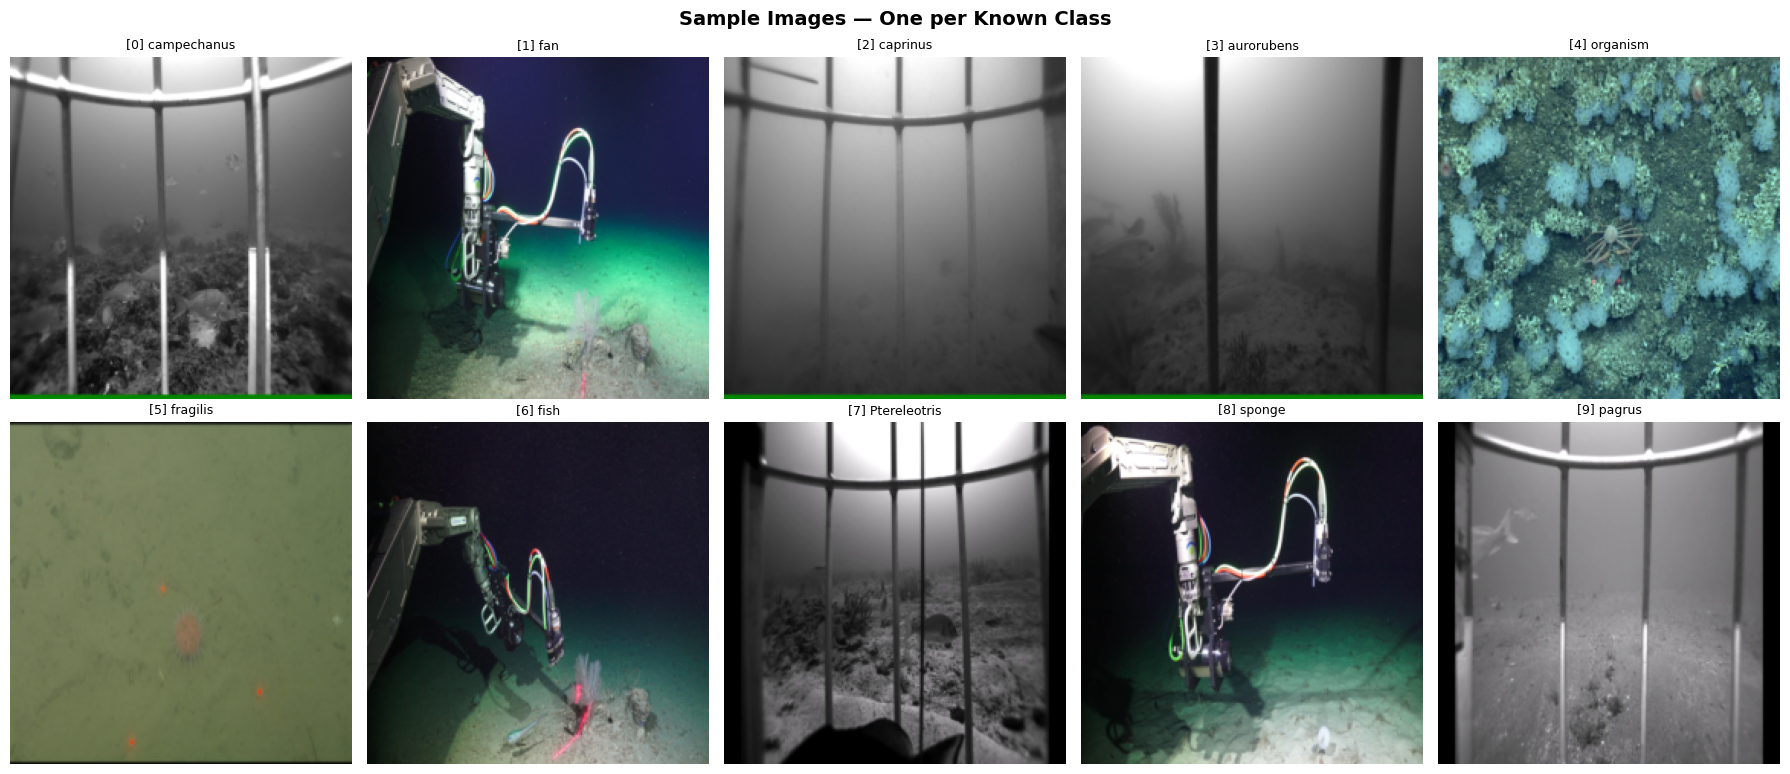

✅ Sample grid saved → sample_images.png


In [9]:
# Plot a grid of sample images from the training set (sanity check)

set_seed()
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

# Un-normalize for display
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

for ax, class_idx in zip(axes, range(NUM_CLASSES)):
    class_rows = train_df[train_df["label"] == class_idx]
    if len(class_rows) == 0:
        ax.axis("off")
        continue
    sample_path = class_rows.sample(1, random_state=SEED)["path"].values[0]
    img, _ = MarineDataset(
        pd.DataFrame([{"path": sample_path, "label": class_idx, "is_ood": False}]),
        transform=eval_transform
    )[0]
    img_display = inv_normalize(img).permute(1, 2, 0).numpy()
    img_display = np.clip(img_display, 0, 1)
    ax.imshow(img_display)
    short_name = CLASS_NAMES[class_idx].split()[-1]   # last word of species name
    ax.set_title(f"[{class_idx}] {short_name}", fontsize=9)
    ax.axis("off")

plt.suptitle("Sample Images — One per Known Class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("sample_images.png", dpi=150)
plt.show()
print("✅ Sample grid saved → sample_images.png")

Model A: Custom CNN Architecture

In [10]:
#  Model A: CNN from scratch
class ConvBlock(nn.Module):
    """Conv → BN → ReLU → MaxPool"""
    def __init__(self, in_ch, out_ch, pool=True):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if pool:
            layers.append(nn.MaxPool2d(2, 2))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)
class MarineCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32),    # 224 → 112
            ConvBlock(32,  64),    # 112 →  56
            ConvBlock(64,  128),   #  56 →  28
            ConvBlock(128, 256),   #  28 →  14
        )
        self.gap = nn.AdaptiveAvgPool2d(1)   # 14×14 → 1×1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        return self.classifier(x)


# Quick parameter count
model_a = MarineCNN().to(DEVICE)
total_params = sum(p.numel() for p in model_a.parameters() if p.requires_grad)
print(f"✅ Model A — MarineCNN")
print(f"   Trainable parameters : {total_params:,}")
print(model_a)

✅ Model A — MarineCNN
   Trainable parameters : 457,258
MarineCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05

Training Utility Functions

In [11]:
#  Reusable training loop and evaluation helpers

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_labels


def train_model(model, train_loader, val_loader, optimizer, scheduler=None,
                num_epochs=20, tag="model"):
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    best_weights = None

    for epoch in range(1, num_epochs + 1):
        t_loss, t_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        v_loss, v_acc, _, _ = evaluate(model, val_loader, criterion)

        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        history["train_acc"].append(t_acc)
        history["val_acc"].append(v_acc)

        if scheduler:
            scheduler.step()

        if v_acc > best_val_acc:
            best_val_acc = v_acc
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}

        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:3d}/{num_epochs} | "
                  f"Train Loss: {t_loss:.4f}  Acc: {t_acc:.3f} | "
                  f"Val Loss: {v_loss:.4f}  Acc: {v_acc:.3f}")

    model.load_state_dict(best_weights)   # restore best checkpoint
    print(f"\n✅ [{tag}] Best val acc: {best_val_acc:.4f}")
    return history

Plot Training Curves Utility

In [12]:
#  Reusable curve plotter

def plot_curves(histories: dict, title="Training Curves"):
    """
    histories: dict of {label_string: history_dict}
    Each history_dict has keys: train_loss, val_loss, train_acc, val_acc
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    for label, h in histories.items():
        epochs = range(1, len(h["train_loss"]) + 1)
        ax1.plot(epochs, h["train_loss"], label=f"{label} train")
        ax1.plot(epochs, h["val_loss"],   label=f"{label} val", linestyle="--")
        ax2.plot(epochs, h["train_acc"],  label=f"{label} train")
        ax2.plot(epochs, h["val_acc"],    label=f"{label} val",  linestyle="--")

    ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
    ax1.legend(fontsize=7); ax1.grid(True, alpha=0.3)

    ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy")
    ax2.legend(fontsize=7); ax2.grid(True, alpha=0.3)

    plt.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    fname = title.replace(" ", "_").lower() + ".png"
    plt.savefig(fname, dpi=150)
    plt.show()
    print(f"✅ Saved → {fname}")

Train Model A — Config 1 (LR=1e-3, Batch=32)

In [13]:
#  Model A — Hyperparameter Config 1


set_seed()
NUM_EPOCHS_A = 25

model_a_cfg1 = MarineCNN(num_classes=NUM_CLASSES, dropout=0.5).to(DEVICE)
optimizer_a1 = optim.Adam(model_a_cfg1.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_a1 = optim.lr_scheduler.CosineAnnealingLR(optimizer_a1, T_max=NUM_EPOCHS_A)

print("🚀 Training Model A — Config 1 (Adam, LR=1e-3, Cosine schedule)")
history_a1 = train_model(
    model_a_cfg1, train_loader, val_loader,
    optimizer_a1, scheduler_a1,
    num_epochs=NUM_EPOCHS_A, tag="ModelA-Config1"
)

🚀 Training Model A — Config 1 (Adam, LR=1e-3, Cosine schedule)
  Epoch   1/25 | Train Loss: 1.7692  Acc: 0.365 | Val Loss: 1.6669  Acc: 0.361
  Epoch   5/25 | Train Loss: 1.0467  Acc: 0.580 | Val Loss: 0.8521  Acc: 0.644
  Epoch  10/25 | Train Loss: 0.7973  Acc: 0.680 | Val Loss: 0.7043  Acc: 0.744
  Epoch  15/25 | Train Loss: 0.7158  Acc: 0.723 | Val Loss: 0.6497  Acc: 0.756
  Epoch  20/25 | Train Loss: 0.5789  Acc: 0.768 | Val Loss: 0.5636  Acc: 0.806
  Epoch  25/25 | Train Loss: 0.5621  Acc: 0.793 | Val Loss: 0.5600  Acc: 0.778

✅ [ModelA-Config1] Best val acc: 0.8056


Train Model A — Config 2 (LR=1e-4, SGD+Momentum)

In [14]:
#  Model A — Hyperparameter Config 2

set_seed()
model_a_cfg2 = MarineCNN(num_classes=NUM_CLASSES, dropout=0.4).to(DEVICE)
optimizer_a2 = optim.SGD(model_a_cfg2.parameters(), lr=1e-2,
                          momentum=0.9, nesterov=True, weight_decay=1e-4)
scheduler_a2 = optim.lr_scheduler.StepLR(optimizer_a2, step_size=10, gamma=0.1)

print("🚀 Training Model A — Config 2 (SGD+Nesterov, LR=1e-2, StepLR)")
history_a2 = train_model(
    model_a_cfg2, train_loader, val_loader,
    optimizer_a2, scheduler_a2,
    num_epochs=NUM_EPOCHS_A, tag="ModelA-Config2"
)

🚀 Training Model A — Config 2 (SGD+Nesterov, LR=1e-2, StepLR)
  Epoch   1/25 | Train Loss: 1.9465  Acc: 0.310 | Val Loss: 1.8115  Acc: 0.256
  Epoch   5/25 | Train Loss: 1.0874  Acc: 0.571 | Val Loss: 1.1671  Acc: 0.544
  Epoch  10/25 | Train Loss: 0.8103  Acc: 0.662 | Val Loss: 0.7783  Acc: 0.722
  Epoch  15/25 | Train Loss: 0.7002  Acc: 0.714 | Val Loss: 0.6164  Acc: 0.750
  Epoch  20/25 | Train Loss: 0.6238  Acc: 0.738 | Val Loss: 0.5858  Acc: 0.778
  Epoch  25/25 | Train Loss: 0.6336  Acc: 0.750 | Val Loss: 0.5937  Acc: 0.772

✅ [ModelA-Config2] Best val acc: 0.7833


Plot Model A Curves & Pick Best Config

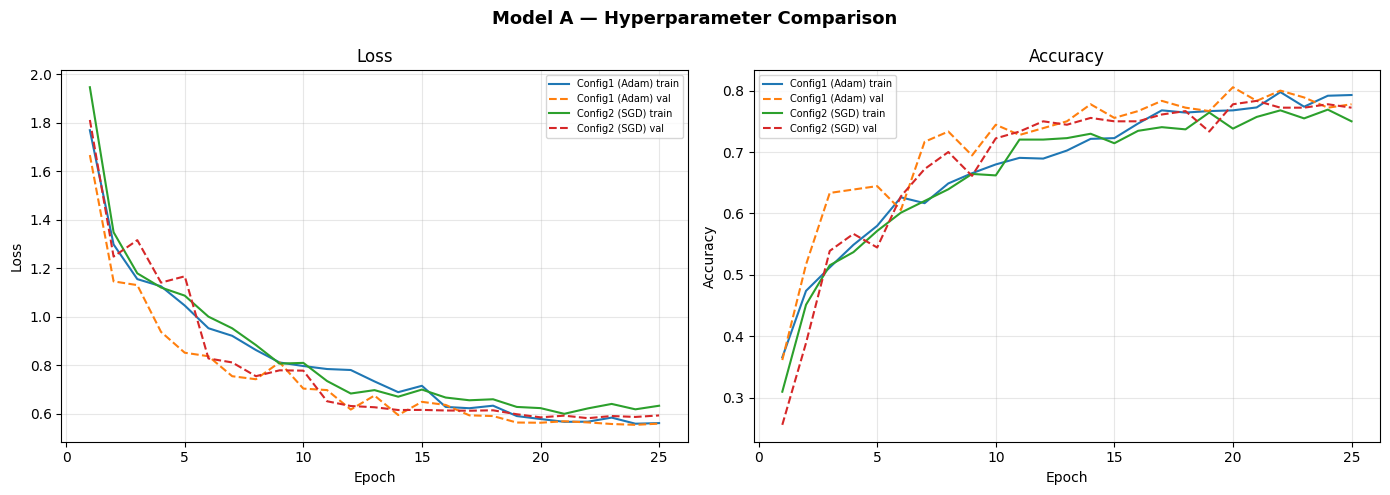

✅ Saved → model_a_—_hyperparameter_comparison.png

📌 Config 1 best val acc : 0.8056
📌 Config 2 best val acc : 0.7833
✅ Selected best Model A config : Config 1 (Adam)


In [15]:
# Cell 15 — Compare the two configurations visually

plot_curves(
    {"Config1 (Adam)": history_a1, "Config2 (SGD)": history_a2},
    title="Model A — Hyperparameter Comparison"
)

# Select best config based on final val accuracy
best_val_a1 = max(history_a1["val_acc"])
best_val_a2 = max(history_a2["val_acc"])
model_a_best = model_a_cfg1 if best_val_a1 >= best_val_a2 else model_a_cfg2

print(f"\n📌 Config 1 best val acc : {best_val_a1:.4f}")
print(f"📌 Config 2 best val acc : {best_val_a2:.4f}")
print(f"✅ Selected best Model A config : {'Config 1 (Adam)' if best_val_a1 >= best_val_a2 else 'Config 2 (SGD)'}")

 Evaluation Utility (Metrics + Confusion Matrix)

In [16]:
#  Full evaluation: per-class metrics, macro F1, confusion matrix
def full_evaluation(model, loader, class_names, tag="Model"):
    criterion = nn.CrossEntropyLoss()
    _, acc, preds, labels = evaluate(model, loader, criterion)

    short_names = [c.split()[-1] for c in class_names]   # last word of species name

    print(f"\n{'='*60}")
    print(f"📊 Evaluation Report — {tag}")
    print(f"{'='*60}")
    print(f"  Overall Accuracy : {acc:.4f}")
    print(f"  Macro F1 Score   : {f1_score(labels, preds, average='macro'):.4f}")
    print()
    print(classification_report(labels, preds, target_names=short_names, digits=4))

    # Confusion matrix
    cm = confusion_matrix(labels, preds)
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=short_names, yticklabels=short_names,
                linewidths=0.5, ax=ax)
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("True", fontsize=12)
    ax.set_title(f"Confusion Matrix — {tag}", fontsize=13, fontweight="bold")
    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    fname = f"confusion_matrix_{tag.replace(' ','_')}.png"
    plt.savefig(fname, dpi=150)
    plt.show()
    print(f"✅ Confusion matrix saved → {fname}")

    return {"accuracy": acc,
            "macro_f1": f1_score(labels, preds, average="macro"),
            "preds": preds, "labels": labels}

Evaluate Model A on Test Set


📊 Evaluation Report — Model A (CNN Scratch)
  Overall Accuracy : 0.8056
  Macro F1 Score   : 0.8047

              precision    recall  f1-score   support

 campechanus     0.8125    0.7222    0.7647        18
         fan     0.8462    0.6111    0.7097        18
    caprinus     1.0000    1.0000    1.0000        18
  aurorubens     0.9333    0.7778    0.8485        18
    organism     0.8000    0.6667    0.7273        18
    fragilis     0.9444    0.9444    0.9444        18
        fish     0.6316    0.6667    0.6486        18
Ptereleotris     0.8571    1.0000    0.9231        18
      sponge     0.6400    0.8889    0.7442        18
      pagrus     0.7000    0.7778    0.7368        18

    accuracy                         0.8056       180
   macro avg     0.8165    0.8056    0.8047       180
weighted avg     0.8165    0.8056    0.8047       180



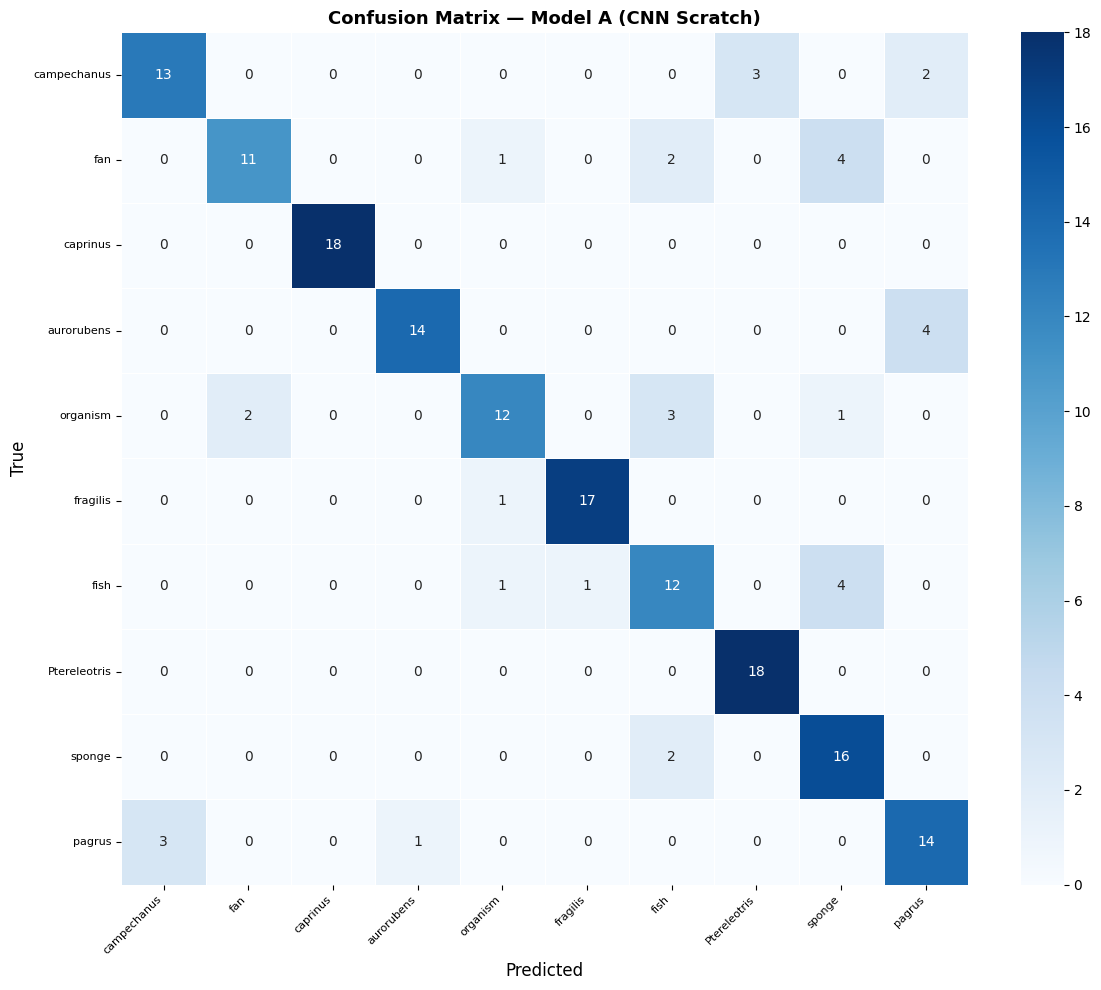

✅ Confusion matrix saved → confusion_matrix_Model_A_(CNN_Scratch).png


In [17]:
# Run full evaluation for the best Model A config on the held-out test set

results_a = full_evaluation(model_a_best, test_loader, CLASS_NAMES, tag="Model A (CNN Scratch)")

Model B: Transfer Learning Setup (ResNet-50)

In [18]:
#  Load pretrained ResNet-50 and define the three TL strategies
def build_resnet(strategy: str, num_classes=NUM_CLASSES):
    """
    strategy:  'feature_extraction' | 'partial_finetune' | 'full_finetune'
    Returns (model, params_to_optimize)
    """
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

    # Replace classification head
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(0.4),
        nn.Linear(512, num_classes)
    )

    if strategy == "feature_extraction":
        # Freeze ALL backbone layers
        for name, param in model.named_parameters():
            if "fc" not in name:
                param.requires_grad = False

    elif strategy == "partial_finetune":
        # Freeze early layers; unfreeze layer3, layer4, and fc
        for name, param in model.named_parameters():
            param.requires_grad = False
        for name, param in model.named_parameters():
            if any(s in name for s in ["layer3", "layer4", "fc"]):
                param.requires_grad = True

    elif strategy == "full_finetune":
        # All parameters trainable
        for param in model.parameters():
            param.requires_grad = True

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    print(f"  [{strategy:20s}]  trainable: {trainable:,} / {total:,}")
    return model.to(DEVICE)


print("🏗️  Building ResNet-50 variants...")
model_fe  = build_resnet("feature_extraction")
model_pft = build_resnet("partial_finetune")
model_fft = build_resnet("full_finetune")

🏗️  Building ResNet-50 variants...
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


  [feature_extraction  ]  trainable: 1,054,218 / 24,562,250
  [partial_finetune    ]  trainable: 23,117,322 / 24,562,250
  [full_finetune       ]  trainable: 24,562,250 / 24,562,250


Train All Three TL Strategies

In [19]:
# Train feature extraction, partial fine-tune, full fine-tune
NUM_EPOCHS_B = 20
#  Feature Extraction
set_seed()
print("🚀 Strategy 1: Feature Extraction")
opt_fe = optim.Adam(filter(lambda p: p.requires_grad, model_fe.parameters()),
                    lr=1e-3, weight_decay=1e-4)
sch_fe = optim.lr_scheduler.CosineAnnealingLR(opt_fe, T_max=NUM_EPOCHS_B)
history_fe = train_model(model_fe, train_loader, val_loader,
                          opt_fe, sch_fe, num_epochs=NUM_EPOCHS_B, tag="FeatureExtraction")
#  Partial Fine-Tuning
set_seed()
print("\n🚀 Strategy 2: Partial Fine-Tuning")
opt_pft = optim.Adam(filter(lambda p: p.requires_grad, model_pft.parameters()),
                     lr=5e-4, weight_decay=1e-4)
sch_pft = optim.lr_scheduler.CosineAnnealingLR(opt_pft, T_max=NUM_EPOCHS_B)
history_pft = train_model(model_pft, train_loader, val_loader,
                           opt_pft, sch_pft, num_epochs=NUM_EPOCHS_B, tag="PartialFineTune")
# Full Fine-Tuning
set_seed()
print("\n🚀 Strategy 3: Full Fine-Tuning")
opt_fft = optim.Adam(model_fft.parameters(), lr=1e-4, weight_decay=1e-4)  # very low LR
sch_fft = optim.lr_scheduler.CosineAnnealingLR(opt_fft, T_max=NUM_EPOCHS_B)
history_fft = train_model(model_fft, train_loader, val_loader,
                           opt_fft, sch_fft, num_epochs=NUM_EPOCHS_B, tag="FullFineTune")

🚀 Strategy 1: Feature Extraction
  Epoch   1/20 | Train Loss: 1.7415  Acc: 0.408 | Val Loss: 0.9596  Acc: 0.694
  Epoch   5/20 | Train Loss: 0.6257  Acc: 0.762 | Val Loss: 0.5717  Acc: 0.811
  Epoch  10/20 | Train Loss: 0.4727  Acc: 0.837 | Val Loss: 0.5115  Acc: 0.828
  Epoch  15/20 | Train Loss: 0.4294  Acc: 0.844 | Val Loss: 0.4694  Acc: 0.828
  Epoch  20/20 | Train Loss: 0.3793  Acc: 0.863 | Val Loss: 0.4357  Acc: 0.856

✅ [FeatureExtraction] Best val acc: 0.8667

🚀 Strategy 2: Partial Fine-Tuning
  Epoch   1/20 | Train Loss: 1.1261  Acc: 0.614 | Val Loss: 1.1977  Acc: 0.733
  Epoch   5/20 | Train Loss: 0.4340  Acc: 0.855 | Val Loss: 0.4722  Acc: 0.839
  Epoch  10/20 | Train Loss: 0.3144  Acc: 0.901 | Val Loss: 0.4226  Acc: 0.833
  Epoch  15/20 | Train Loss: 0.1408  Acc: 0.960 | Val Loss: 0.3034  Acc: 0.911
  Epoch  20/20 | Train Loss: 0.1270  Acc: 0.954 | Val Loss: 0.2919  Acc: 0.906

✅ [PartialFineTune] Best val acc: 0.9167

🚀 Strategy 3: Full Fine-Tuning
  Epoch   1/20 | Train L

Plot TL Curves & Evaluate All Three

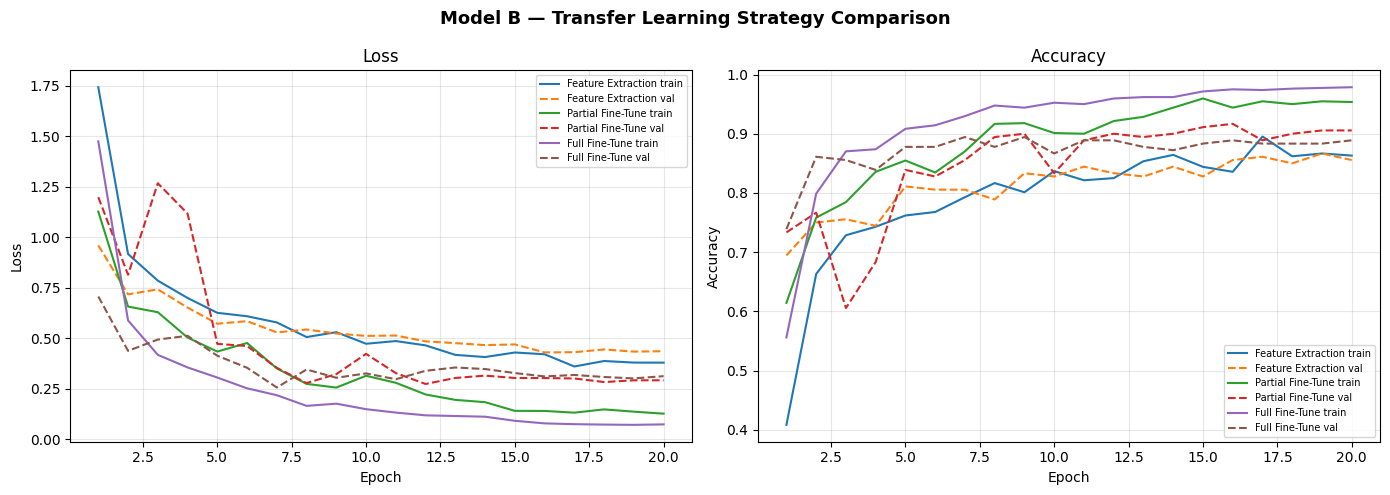

✅ Saved → model_b_—_transfer_learning_strategy_comparison.png

📊 Test Set Evaluation — All TL Strategies

📊 Evaluation Report — ModelB FeatureExtraction
  Overall Accuracy : 0.8667
  Macro F1 Score   : 0.8671

              precision    recall  f1-score   support

 campechanus     0.9444    0.9444    0.9444        18
         fan     0.7143    0.8333    0.7692        18
    caprinus     0.9474    1.0000    0.9730        18
  aurorubens     0.9375    0.8333    0.8824        18
    organism     0.7500    0.6667    0.7059        18
    fragilis     1.0000    0.9444    0.9714        18
        fish     0.9286    0.7222    0.8125        18
Ptereleotris     0.9474    1.0000    0.9730        18
      sponge     0.6818    0.8333    0.7500        18
      pagrus     0.8889    0.8889    0.8889        18

    accuracy                         0.8667       180
   macro avg     0.8740    0.8667    0.8671       180
weighted avg     0.8740    0.8667    0.8671       180



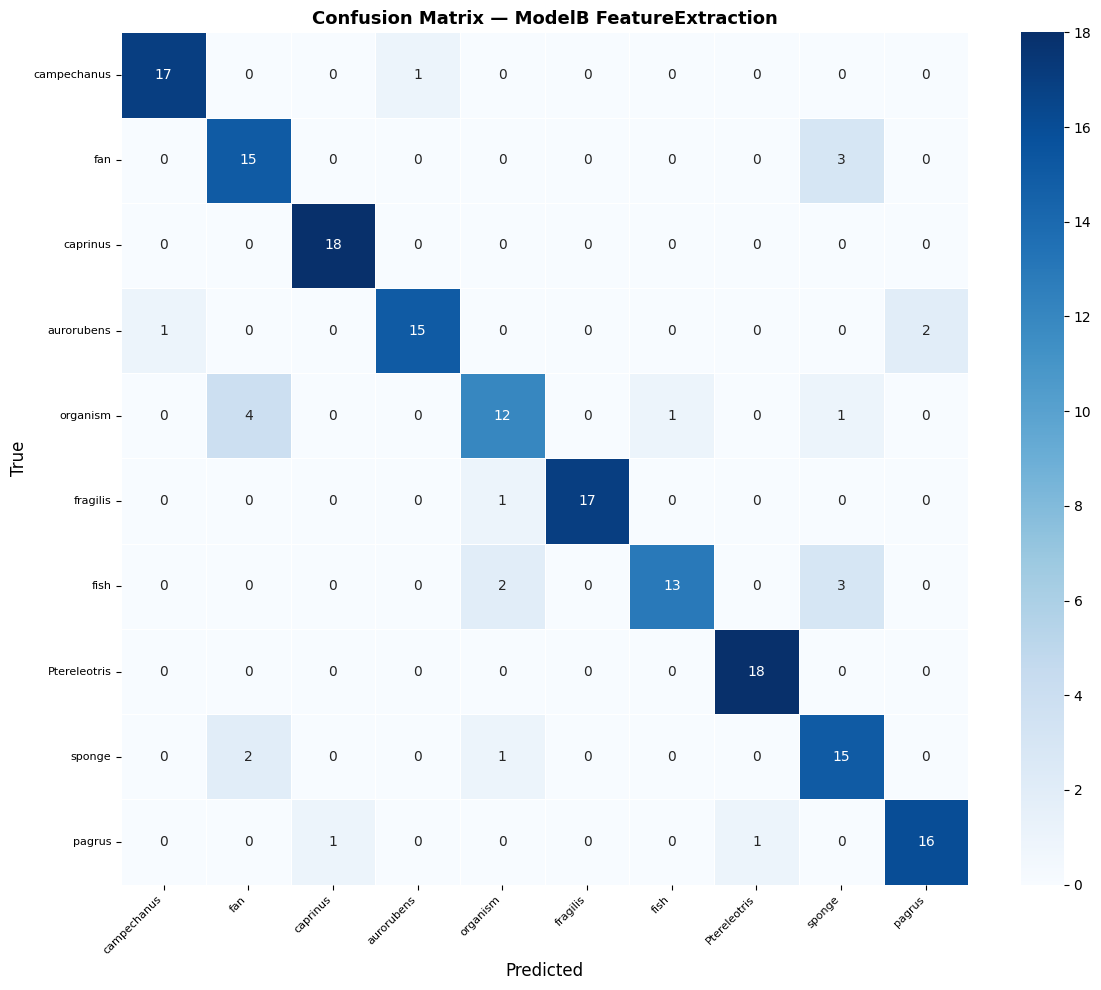

✅ Confusion matrix saved → confusion_matrix_ModelB_FeatureExtraction.png

📊 Evaluation Report — ModelB PartialFineTune
  Overall Accuracy : 0.9389
  Macro F1 Score   : 0.9384

              precision    recall  f1-score   support

 campechanus     1.0000    1.0000    1.0000        18
         fan     0.9444    0.9444    0.9444        18
    caprinus     1.0000    1.0000    1.0000        18
  aurorubens     1.0000    0.8889    0.9412        18
    organism     0.9375    0.8333    0.8824        18
    fragilis     0.9474    1.0000    0.9730        18
        fish     0.8750    0.7778    0.8235        18
Ptereleotris     1.0000    1.0000    1.0000        18
      sponge     0.8095    0.9444    0.8718        18
      pagrus     0.9000    1.0000    0.9474        18

    accuracy                         0.9389       180
   macro avg     0.9414    0.9389    0.9384       180
weighted avg     0.9414    0.9389    0.9384       180



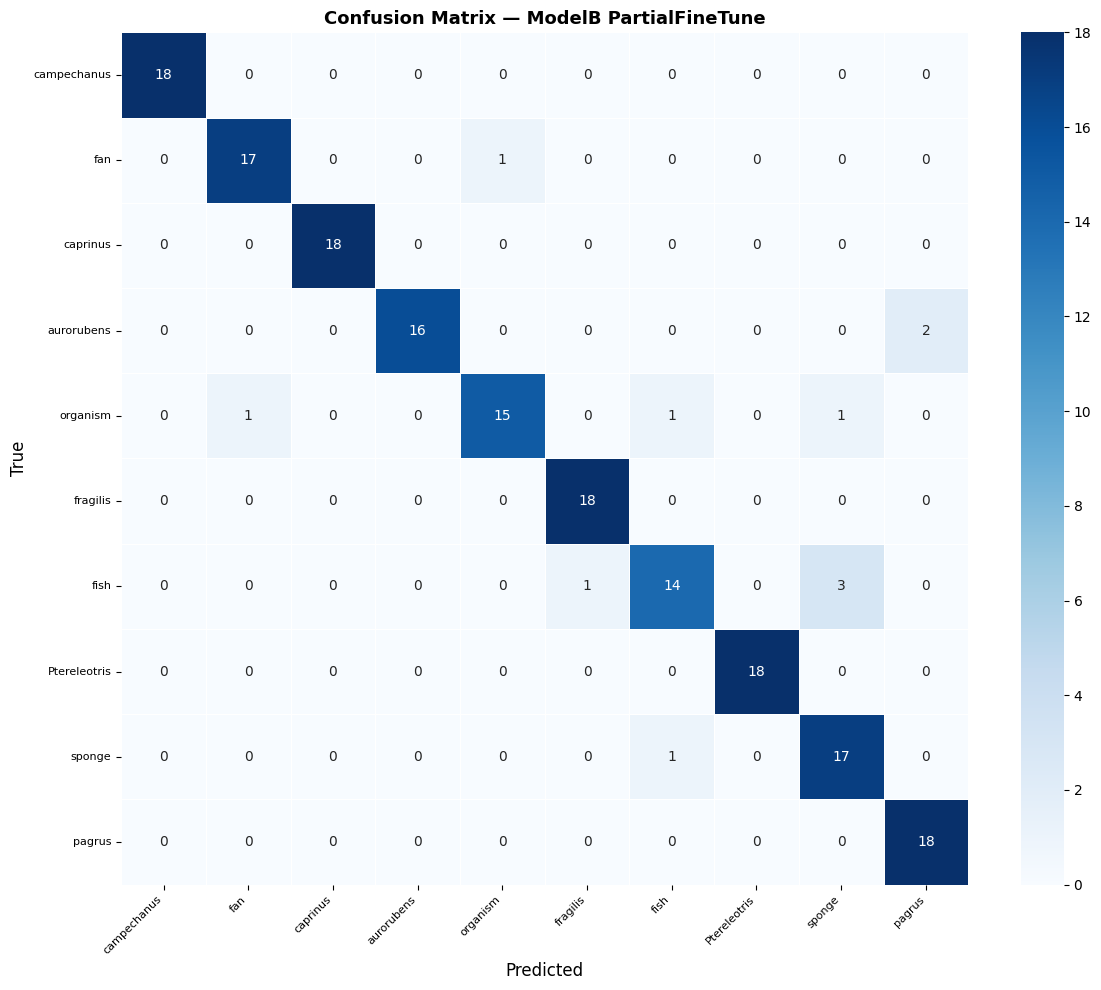

✅ Confusion matrix saved → confusion_matrix_ModelB_PartialFineTune.png

📊 Evaluation Report — ModelB FullFineTune
  Overall Accuracy : 0.9278
  Macro F1 Score   : 0.9266

              precision    recall  f1-score   support

 campechanus     1.0000    1.0000    1.0000        18
         fan     0.9000    1.0000    0.9474        18
    caprinus     1.0000    1.0000    1.0000        18
  aurorubens     1.0000    0.8889    0.9412        18
    organism     0.8750    0.7778    0.8235        18
    fragilis     1.0000    1.0000    1.0000        18
        fish     0.8125    0.7222    0.7647        18
Ptereleotris     1.0000    1.0000    1.0000        18
      sponge     0.8000    0.8889    0.8421        18
      pagrus     0.9000    1.0000    0.9474        18

    accuracy                         0.9278       180
   macro avg     0.9288    0.9278    0.9266       180
weighted avg     0.9287    0.9278    0.9266       180



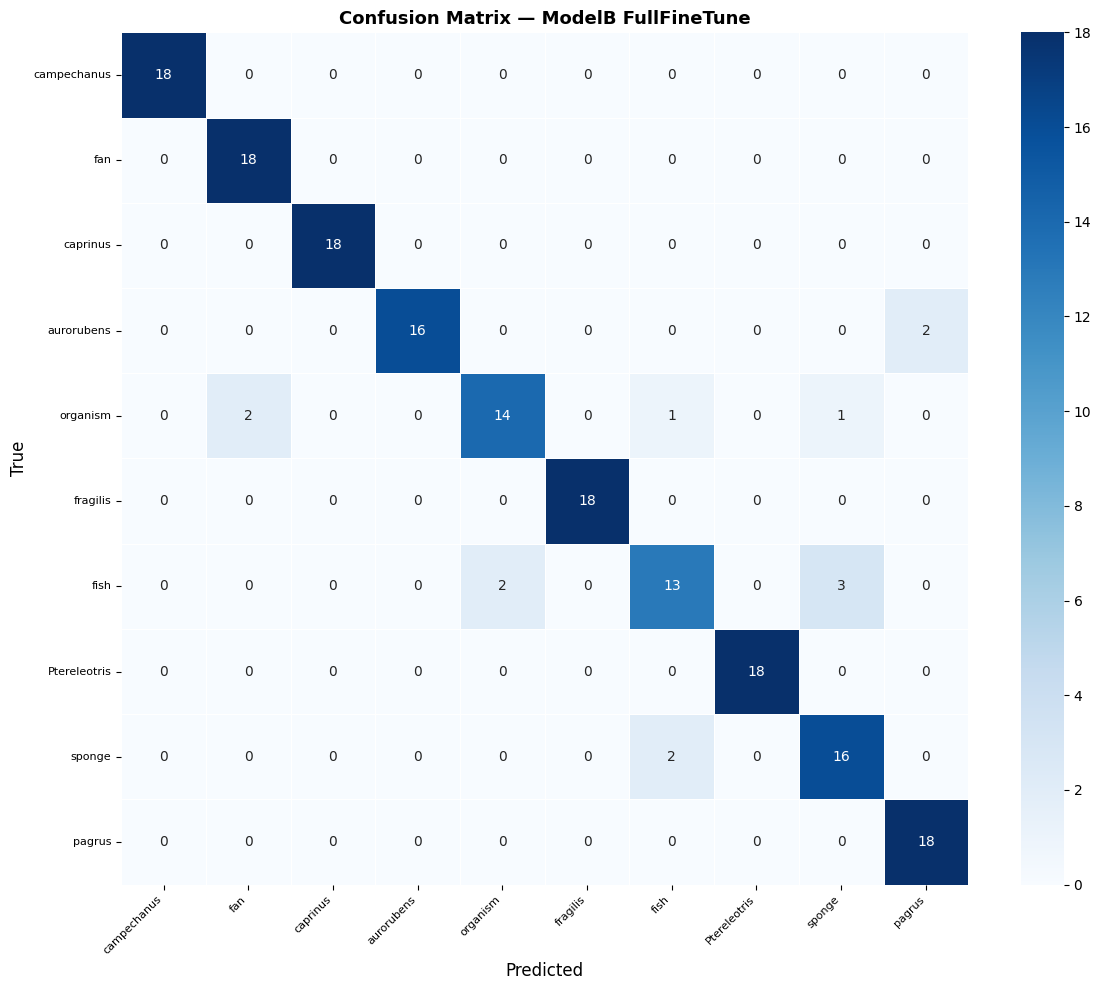

✅ Confusion matrix saved → confusion_matrix_ModelB_FullFineTune.png


In [20]:
#  Visualise and evaluate all three transfer learning strategies

plot_curves(
    {"Feature Extraction": history_fe,
     "Partial Fine-Tune" : history_pft,
     "Full Fine-Tune"    : history_fft},
    title="Model B — Transfer Learning Strategy Comparison"
)

print("\n" + "="*60)
print("📊 Test Set Evaluation — All TL Strategies")
print("="*60)

results_fe  = full_evaluation(model_fe,  test_loader, CLASS_NAMES, tag="ModelB FeatureExtraction")
results_pft = full_evaluation(model_pft, test_loader, CLASS_NAMES, tag="ModelB PartialFineTune")
results_fft = full_evaluation(model_fft, test_loader, CLASS_NAMES, tag="ModelB FullFineTune")

 OOD Detection

🎯 Best OOD threshold : 0.963  (F1 = 0.7546)

📊 OOD Detection Results (threshold = 0.963)
   Precision : 0.7469
   Recall    : 0.7625
   F1 Score  : 0.7546


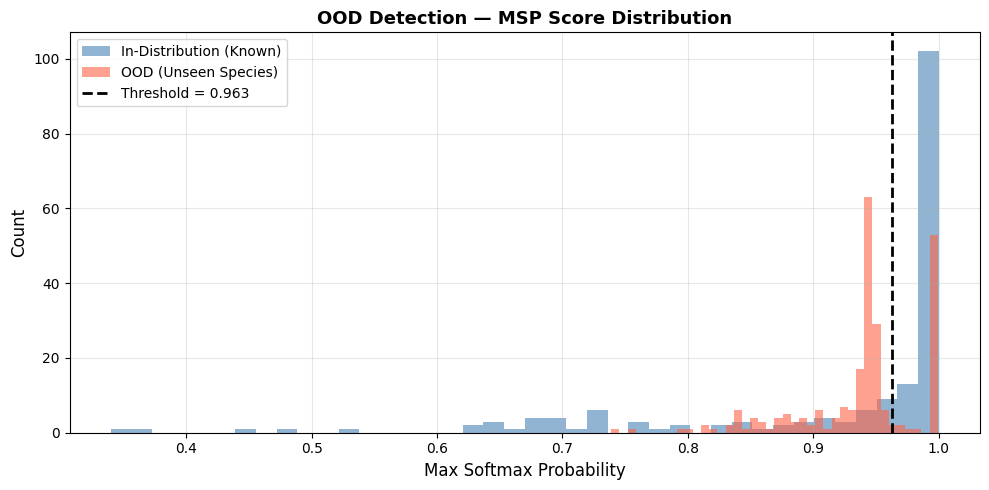

✅ OOD plot saved → ood_detection.png


In [21]:
# Out-of-Distribution Detection
def get_max_softmax_scores(model, loader):
    """Return max softmax probability for every image in loader."""
    model.eval()
    scores = []
    with torch.no_grad():
        for imgs, _ in loader:
            imgs = imgs.to(DEVICE)
            logits = model(imgs)
            probs  = F.softmax(logits, dim=1)
            scores.extend(probs.max(dim=1).values.cpu().numpy())
    return np.array(scores)
ood_model = model_fft
known_scores = get_max_softmax_scores(ood_model, test_loader)
ood_scores   = get_max_softmax_scores(ood_model, ood_loader)
y_true  = np.array([0] * len(known_scores) + [1] * len(ood_scores))
all_msp = np.concatenate([known_scores, ood_scores])
thresholds = np.linspace(0.1, 0.99, 200)
best_thresh, best_f1 = 0.5, 0.0

for t in thresholds:
    y_pred = (all_msp < t).astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thresh = f1, t
print(f"🎯 Best OOD threshold : {best_thresh:.3f}  (F1 = {best_f1:.4f})")

# Final evaluation at best threshold
y_pred_ood = (all_msp < best_thresh).astype(int)
prec = precision_score(y_true, y_pred_ood, zero_division=0)
rec  = recall_score(y_true, y_pred_ood, zero_division=0)
f1   = f1_score(y_true, y_pred_ood, zero_division=0)

print(f"\n📊 OOD Detection Results (threshold = {best_thresh:.3f})")
print(f"   Precision : {prec:.4f}")
print(f"   Recall    : {rec:.4f}")
print(f"   F1 Score  : {f1:.4f}")

# Score distribution plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(known_scores, bins=40, alpha=0.6, label="In-Distribution (Known)", color="steelblue")
ax.hist(ood_scores,   bins=40, alpha=0.6, label="OOD (Unseen Species)",    color="tomato")
ax.axvline(best_thresh, color="black", linestyle="--", linewidth=2,
           label=f"Threshold = {best_thresh:.3f}")
ax.set_xlabel("Max Softmax Probability", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.set_title("OOD Detection — MSP Score Distribution", fontsize=13, fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("ood_detection.png", dpi=150)
plt.show()
print("✅ OOD plot saved → ood_detection.png")

Final Summary Table

In [22]:
# Consolidated results summary across all models

summary_data = {
    "Model"         : ["CNN Scratch",  "TL: Feature Ext.", "TL: Partial FT", "TL: Full FT"],
    "Val Acc (best)": [
        max(history_a1["val_acc"] if best_val_a1 >= best_val_a2 else history_a2["val_acc"]),
        max(history_fe["val_acc"]),
        max(history_pft["val_acc"]),
        max(history_fft["val_acc"]),
    ],
    "Test Acc"  : [results_a["accuracy"],   results_fe["accuracy"],
                   results_pft["accuracy"],  results_fft["accuracy"]],
    "Macro F1"  : [results_a["macro_f1"],   results_fe["macro_f1"],
                   results_pft["macro_f1"],  results_fft["macro_f1"]],
}

summary_df = pd.DataFrame(summary_data)
summary_df[["Val Acc (best)", "Test Acc", "Macro F1"]] = \
    summary_df[["Val Acc (best)", "Test Acc", "Macro F1"]].round(4)

print("\n" + "="*65)
print("📋 FINAL RESULTS SUMMARY")
print("="*65)
print(summary_df.to_string(index=False))
print("="*65)

print(f"\n🔍 OOD Detection  Precision={prec:.4f}  Recall={rec:.4f}  F1={f1:.4f}")


📋 FINAL RESULTS SUMMARY
           Model  Val Acc (best)  Test Acc  Macro F1
     CNN Scratch          0.8056    0.8056    0.8047
TL: Feature Ext.          0.8667    0.8667    0.8671
  TL: Partial FT          0.9167    0.9389    0.9384
     TL: Full FT          0.8944    0.9278    0.9266

🔍 OOD Detection  Precision=0.7469  Recall=0.7625  F1=0.7546


Save Models & Requirements

In [23]:
#Save model weights and generate requirements.txt

torch.save(model_a_best.state_dict(), "model_a_best.pth")
torch.save(model_fft.state_dict(),    "model_b_full_finetune.pth")
print("✅ Model weights saved")

requirements = """torch>=2.0.0
torchvision>=0.15.0
numpy>=1.24.0
pandas>=2.0.0
matplotlib>=3.7.0
seaborn>=0.12.0
scikit-learn>=1.3.0
Pillow>=9.5.0
requests>=2.28.0
tqdm>=4.65.0
fathomnet>=0.3.0
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("✅ requirements.txt saved")
print("\n📦 All deliverables ready:")
print("   • Marine_Species_Classification.ipynb")
print("   • requirements.txt")
print("   • model_a_best.pth")
print("   • model_b_full_finetune.pth")
print("   • sample_images.png")
print("   • confusion_matrix_*.png")
print("   • ood_detection.png")

✅ Model weights saved
✅ requirements.txt saved

📦 All deliverables ready:
   • Marine_Species_Classification.ipynb
   • requirements.txt
   • model_a_best.pth
   • model_b_full_finetune.pth
   • sample_images.png
   • confusion_matrix_*.png
   • ood_detection.png
